# Diagnóstico de Cáncer de Mama Wisconsin con KNN y Validación Cruzada

**Fuente original:** https://www.geeksforgeeks.org/machine-learning/ml-kaggle-breast-cancer-wisconsin-diagnosis-using-knn/

**Modificador y ejecutor:** Carlos Francisco Montoya Urzúa

---

##Dataset
El dataset es proporcionado por Kaggle desde el repositorio UCI Machine Learning, en uno de sus desafíos. Es un dataset de pacientes con cáncer de mama con tumores **Malignos** y **Benignos**.

El algoritmo **K-Nearest Neighbors (KNN)** se utiliza para predecir si un paciente tiene cáncer (tumor Maligno) o no (tumor Benigno).

**Implementación del algoritmo KNN para clasificación.**

---
**Descargar el dataset:** https://media.geeksforgeeks.org/wp-content/uploads/20240919120521/data.csv

## Importar Librerías

In [22]:
# álgebra lineal
import numpy as np

# procesamiento de datos
import pandas as pd

# visualización
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier

## Cargar el Dataset

In [23]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

print("Path to dataset files:", path)

csv_path = os.path.join(
    path,
    "data.csv"
)
#df = pd.read_csv("data.csv")
df = pd.read_csv(
    csv_path,
    encoding='latin-1',
    header=0  #Esto asegura que tome la primer fila como encabezados
)
print(df.head())

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Path to dataset files: /kaggle/input/breast-cancer-wisconsin-data
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.

OTRA FORMA DE CARGAR EL DATASET SI NO SE CONOCE EL NOMBRE DEL ARCHIVO

In [5]:
'''import kagglehub
import os
import pandas as pd

# 1. Descargar la última versión del dataset
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Ruta de los archivos del dataset:", path)

# 2. Listar los archivos para ver qué descargó exactamente
archivos = os.listdir(path)
print("Archivos encontrados en la carpeta:", archivos)

# 3. Buscar automáticamente el primer archivo .csv que encuentre
csv_file = next((f for f in archivos if f.endswith('.csv')), None)

if csv_file:
    csv_path = os.path.join(path, csv_file)
    print(f"Cargando el archivo: {csv_file}")

    # 4. Leer el CSV (este dataset específico TIENE encabezados,
    # así que quitamos 'header=None' para que lea bien los nombres de las columnas)
    df = pd.read_csv(csv_path)

    print("\nPrimeras filas del dataset:")
    print(df.head())
else:
    print("¡Error! No se encontró ningún archivo CSV en la ruta descrita.")'''

100%|██████████| 48.6k/48.6k [00:00<00:00, 33.6MB/s]

Extracting files...
Ruta de los archivos del dataset: /root/.cache/kagglehub/datasets/uciml/breast-cancer-wisconsin-data/versions/2
Archivos encontrados en la carpeta: ['data.csv']
Cargando el archivo: data.csv

Primeras filas del dataset:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974  

**Salida esperada:**

Se mostrarán las primeras filas del dataset con columnas como `id`, `diagnosis`, `radius_mean`, `texture_mean`, entre otras.

## Información del Dataset

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

**Salida esperada:**

```
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
id                         569 non-null int64
diagnosis                  569 non-null object
radius_mean                569 non-null float64
texture_mean               569 non-null float64
perimeter_mean             569 non-null float64
area_mean                  569 non-null float64
smoothness_mean            569 non-null float64
compactness_mean           569 non-null float64
concavity_mean             569 non-null float64
concave points_mean        569 non-null float64
symmetry_mean              569 non-null float64
fractal_dimension_mean     569 non-null float64
radius_se                  569 non-null float64
texture_se                 569 non-null float64
perimeter_se               569 non-null float64
area_se                    569 non-null float64
smoothness_se              569 non-null float64
compactness_se             569 non-null float64
concavity_se               569 non-null float64
concave points_se          569 non-null float64
symmetry_se                569 non-null float64
fractal_dimension_se       569 non-null float64
radius_worst               569 non-null float64
texture_worst              569 non-null float64
perimeter_worst            569 non-null float64
area_worst                 569 non-null float64
smoothness_worst           569 non-null float64
compactness_worst          569 non-null float64
concavity_worst            569 non-null float64
concave points_worst       569 non-null float64
symmetry_worst             569 non-null float64
fractal_dimension_worst    569 non-null float64
Unnamed: 32                0 non-null float64
dtypes: float64(31), int64(1), object(1)
memory usage: 146.8+ KB
```

## Eliminar Columnas Irrelevantes

Eliminamos las columnas `'id'` y `'Unnamed: 32'` ya que no tienen ningún rol en la predicción.

In [25]:
df.drop(['Unnamed: 32', 'id'], axis=1)
print(df.shape)

(569, 33)


**Salida esperada:**
```
(569, 31)
```

## Convertir el Diagnóstico a Valor Numérico

Convertimos los valores `'M'` y `'B'` de la columna `diagnosis` a valores numéricos:
- **M (Maligno) = 1**
- **B (Benigno) = 0**

In [26]:
def diagnosis_value(diagnosis):
    if diagnosis == 'M':
        return 1
    else:
        return 0

df['diagnosis'] = df['diagnosis'].apply(diagnosis_value)

## Visualización: Radio Medio vs Textura Media

Graficamos la relación entre `radius_mean` y `texture_mean`, coloreando por diagnóstico.

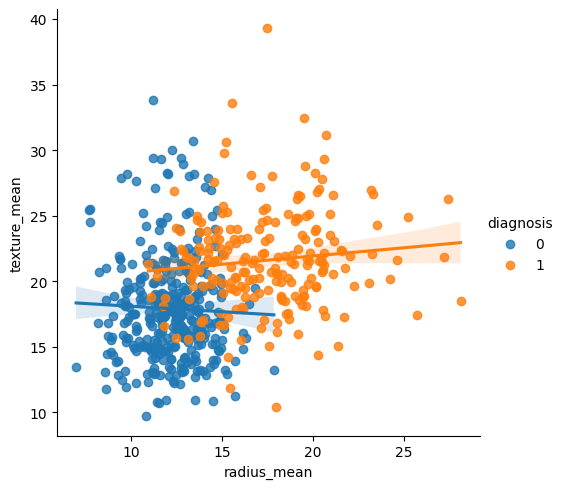

In [27]:
sns.lmplot(x='radius_mean', y='texture_mean', hue='diagnosis', data=df)

**Salida esperada:** Gráfica de dispersión con línea de regresión para tumores malignos (1) y benignos (0), mostrando que los tumores malignos tienden a tener mayor radio medio.

## Visualización: Suavidad Media vs Compacidad Media

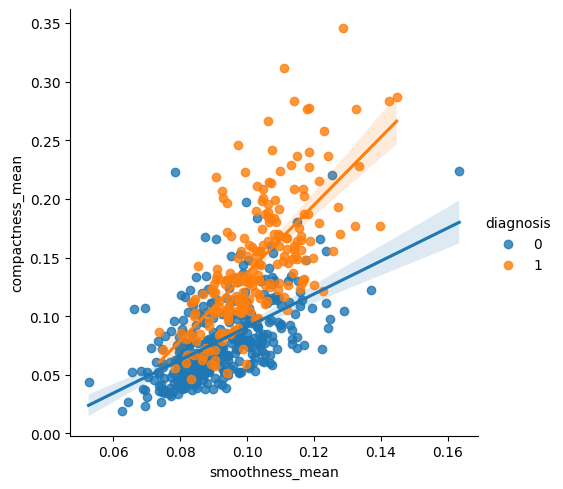

In [28]:
sns.lmplot(x='smoothness_mean', y='compactness_mean',
           data=df, hue='diagnosis')

**Salida esperada:** Gráfica de dispersión que muestra la relación entre suavidad y compacidad media según el tipo de tumor.

## Datos de Entrada y Salida

In [32]:
if 'Unnamed: 32' in df.columns:
    df = df.drop(columns=['Unnamed: 32'])

#X = np.array(df.iloc[:, 1:])
X = np.array(
    df.drop(
        columns=['id','diagnosis']
    )
)
y = np.array(df['diagnosis'])

## División de Datos en Entrenamiento y Prueba

In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

## Usar Sklearn para Entrenar el Modelo KNN

In [34]:
knn = KNeighborsClassifier(n_neighbors=13)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=13)

**Salida esperada:**
```
KNeighborsClassifier(algorithm='auto', leaf_size=30,
             metric='minkowski', metric_params=None,
             n_jobs=None, n_neighbors=13, p=2,
             weights='uniform')
```

## Puntuación de Predicción

In [35]:
knn.score(X_test, y_test)

0.9627659574468085

**Salida esperada:**
```
0.9627659574468085
```

## Realizar Validación Cruzada

Aplicamos validación cruzada de 10 pliegues (*10-fold cross validation*) para encontrar el valor óptimo de `k`.

In [36]:
neighbors = []
cv_scores = []

from sklearn.model_selection import cross_val_score

# realizar validación cruzada de 10 pliegues
for k in range(1, 51, 2):
    neighbors.append(k)
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(
        knn, X_train, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

## Error de Clasificación Incorrecta vs k

Calculamos el error de clasificación incorrecta (*Misclassification Error*) para cada valor de `k` y graficamos los resultados para determinar el valor óptimo.

El número óptimo de vecinos es 13 


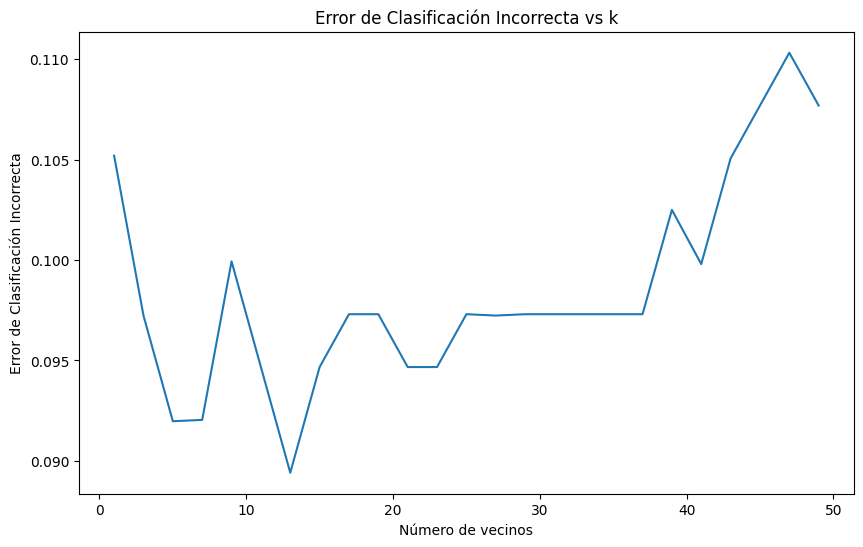

In [37]:
MSE = [1 - x for x in cv_scores]

# determinar el k óptimo
optimal_k = neighbors[MSE.index(min(MSE))]
print('El número óptimo de vecinos es %d ' % optimal_k)

# graficar el error de clasificación incorrecta vs k
plt.figure(figsize=(10, 6))
plt.plot(neighbors, MSE)
plt.xlabel('Número de vecinos')
plt.ylabel('Error de Clasificación Incorrecta')
plt.title('Error de Clasificación Incorrecta vs k')
plt.show()

**Salida esperada:**
```
El número óptimo de vecinos es 13
```
Y una gráfica que muestra cómo varía el error de clasificación incorrecta conforme aumenta el número de vecinos `k`, con un mínimo en `k = 13`.

---



##Intento con escalamiento de caracteristicas

In [41]:
from sklearn.preprocessing import StandardScaler

# Crear el escalador estándar (resta la media y divide por la desviación estándar)
scaler = StandardScaler()

# Ajustar y transformar los datos de entrenamiento, y transformar los de prueba
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=49)

### Puntuación de Predicción

In [40]:
knn.score(X_test_scaled, y_test)

0.9414893617021277

Resulta una presición peor. Por tanto, se rechaza el escalado.

##AGREGADO: Matriz de Confusión y Reporte de Clasificación


--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       121
           1       0.98      0.88      0.93        67

    accuracy                           0.95       188
   macro avg       0.96      0.94      0.95       188
weighted avg       0.95      0.95      0.95       188



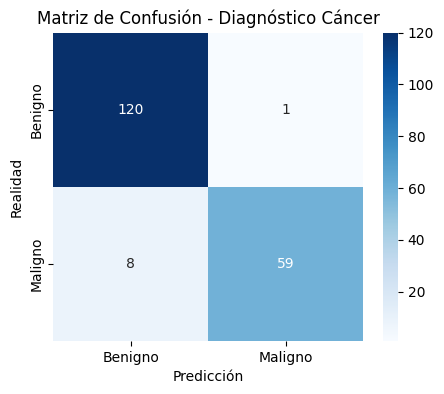

In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predecir con los datos de prueba NO escalados
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

# 1. Imprimir reporte detallado (Precisión, Recall, F1-Score)
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))

# 2. Graficar una Matriz de Confusión visual
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benigno', 'Maligno'],
            yticklabels=['Benigno', 'Maligno'])
plt.ylabel('Realidad')
plt.xlabel('Predicción')
plt.title('Matriz de Confusión - Diagnóstico Cáncer')
plt.show()

## Conclusión

El algoritmo **KNN** con `k = 13` vecinos logra una precisión de aproximadamente **96.3%** en la detección del cáncer de mama. La **validación cruzada de 10 pliegues** nos permite confirmar que este valor de `k` es el óptimo, ya que minimiza el error de clasificación incorrecta.

Este enfoque demuestra cómo los algoritmos de machine learning pueden aplicarse eficazmente en problemas de diagnóstico médico, ofreciendo una herramienta de apoyo para la detección temprana del cáncer de mama.